# Day 16 — RAG Diagnostics and Debugging

A RAG pipeline can fail silently: confident, wrong answers with no error message. This notebook takes the Day 15 pipeline (MiniLM embeddings + FAISS + LangChain prompt + local Qwen2.5-1.5B) and diagnoses it systematically.

**Plan**
1. A 15-query test suite aimed at five failure modes (3 queries each)
2. Log every call (chunks, scores, answer) to `rag_results.json`
3. Classify each result and explain the cause in one sentence
4. Trace failures back to a chunking or embedding decision
5. Implement fixes (chunk overlap, similarity threshold, refined prompt) and re-measure
6. Retrieval-vs-answer scorecard (1 to 5) before and after

**Runtime:** Colab → Runtime → Change runtime type → **T4 GPU**.

**One difference from Day 15:** the knowledge base is now 4 short *documents* split by a word-window chunker. Day 15 used one fact per chunk, so chunking could never fail. Real RAG systems split text, and splitting is where many failures start.

In [1]:
!pip install -q faiss-cpu sentence-transformers langchain-core transformers accelerate numpy pandas matplotlib

In [2]:
import os, re, json, datetime, textwrap
import numpy as np, pandas as pd, faiss
from sentence_transformers import SentenceTransformer
from langchain_core.prompts import PromptTemplate

# ---- the pipeline decisions we will diagnose ----
CHUNK_SIZE = 40              # words per chunk
OVERLAP = 0                  # words shared by neighbouring chunks
TOP_K = 3                    # chunks retrieved per query
CONTEXT_BUDGET_WORDS = 100   # max words of context sent to the LLM (simulates a tight context window)
LOG_PATH = "rag_results.json"

embedder = SentenceTransformer("all-MiniLM-L6-v2")
def embed(texts):
    return np.asarray(embedder.encode(list(texts), normalize_embeddings=True), dtype="float32")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (3 outputs left out)

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

## 1. Knowledge base: four documents, split into chunks
`chunk_words(text, size, overlap)` slides a window over the words of each document. With `overlap=0` a sentence that sits on a boundary gets cut in half. `build_index()` embeds the chunks and stores them in FAISS.

In [3]:
DOCS = {
"company_overview": "Veridia Labs was founded in 2019 in Srinagar by Dr. Hana Mir and Taj Bhat. The company's headquarters is on the third floor of the Dal View Building. Dr. Hana Mir serves as chief executive officer, and Taj Bhat serves as chief technology officer. As of 2026 the company employs 42 people, and 12 of them are engineers. In March 2026 Veridia opened a second office in Anantnag. The company reported annual revenue of 3.2 crore rupees in 2025. Its flagship product is Kesar, a crop-yield forecasting app built for saffron farmers.",
"pricing_plans": "Kesar is sold in two plans. The Basic plan costs 499 rupees per month and refreshes satellite imagery every 14 days. The Pro plan costs 1,299 rupees per month and refreshes satellite imagery every 3 days. Only the Pro plan includes API access, which is limited to 5,000 requests per day. The Basic plan has no API access at all. Customers who choose the annual plan pay for 10 months and get 2 months free. Farmers who refer a friend receive one free month of the Basic plan.",
"refunds_support": "Refund policy: the Basic plan can be refunded within 7 days of purchase, and the Pro plan can be refunded within 14 days of purchase. Refunds are not available after these windows. Customer support is available Monday to Friday, from 9 am to 6 pm IST, and there is no weekend support. Scheduled maintenance happens on Sundays from 2 am to 4 am IST, during which the app may be unavailable.",
"model_data": "Kesar's forecasting model is called Zafran-2. It was trained on 6 years of harvest records collected from 1,200 local farms. On validation data, Zafran-2 predicts harvest yield with an error of about 8 percent. Kesar supports three languages: Urdu, Kashmiri and English. Farm data is stored on servers in the Mumbai region and is deleted within 30 days after an account is closed.",
}

def chunk_words(text, size, overlap):
    words = text.split(); step = size - overlap; out = []
    for start in range(0, len(words), step):
        out.append(" ".join(words[start:start + size]))
        if start + size >= len(words): break
    return out

STATE = {}
def build_index(size, overlap):
    chunks = []
    for doc, text in DOCS.items():
        for piece in chunk_words(text, size, overlap):
            chunks.append({"chunk_id": len(chunks), "doc": doc, "text": piece})
    vecs = embed([c["text"] for c in chunks])
    index = faiss.IndexFlatL2(vecs.shape[1]); index.add(vecs)
    STATE.update(chunks=chunks, index=index, size=size, overlap=overlap)
    print(f"chunk_size={size}, overlap={overlap}: {len(chunks)} chunks, index size {index.ntotal}, vectors {vecs.shape} {vecs.dtype}")

build_index(CHUNK_SIZE, OVERLAP)
for c in STATE["chunks"]:
    print(f"[{c['chunk_id']:2d}] ({c['doc']}) {c['text']}\n")

chunk_size=40, overlap=0: 10 chunks, index size 10, vectors (10, 384) float32
[ 0] (company_overview) Veridia Labs was founded in 2019 in Srinagar by Dr. Hana Mir and Taj Bhat. The company's headquarters is on the third floor of the Dal View Building. Dr. Hana Mir serves as chief executive officer, and Taj Bhat serves

[ 1] (company_overview) as chief technology officer. As of 2026 the company employs 42 people, and 12 of them are engineers. In March 2026 Veridia opened a second office in Anantnag. The company reported annual revenue of 3.2 crore rupees in 2025. Its

[ 2] (company_overview) flagship product is Kesar, a crop-yield forecasting app built for saffron farmers.

[ 3] (pricing_plans) Kesar is sold in two plans. The Basic plan costs 499 rupees per month and refreshes satellite imagery every 14 days. The Pro plan costs 1,299 rupees per month and refreshes satellite imagery every 3 days. Only the Pro plan

[ 4] (pricing_plans) includes API access, which is limited to 5,000 reque

## 2. The LLM (same local model as Day 15)

In [4]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
tok = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, torch_dtype="auto", device_map="auto")

def call_llm(system, user, max_new_tokens=150):
    messages = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    text = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tok(text, return_tensors="pt").to(llm.device)
    with torch.no_grad():
        out = llm.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
    return tok.decode(out[0][inputs.input_ids.shape[1]:], skip_special_tokens=True).strip()

print(call_llm("You are a helpful assistant.", "Say hello in five words."))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Hello there! How can I assist you today?


## 3. The RAG pipeline with automatic logging
Every call to `rag_answer()` appends one record to `rag_results.json` with: the retrieved chunks (excerpt + distance), whether the context was truncated, the final answer, and a timestamp.

Settings the fixes will change later: `threshold` (refuse when the best chunk is too far away) and `system` (the instructions given to the LLM).

In [5]:
REFUSAL = "I don't know based on the provided documents."
RAG_SYSTEM_V1 = ("You are a careful assistant. Answer the question using ONLY the information in the CONTEXT. "
                 "If the CONTEXT does not contain the answer, reply exactly: " + REFUSAL)
RAG_SYSTEM_V2 = ("You answer questions using ONLY the CONTEXT. Rules: "
                 "(1) Find the sentence in the CONTEXT that states the answer. "
                 "(2) If no sentence states the requested number, date, name or detail, reply exactly: " + REFUSAL + " "
                 "(3) Never combine facts about different things (for example a company-wide number is not an office number). "
                 "(4) For a calculation, write the numbers you use, then the final result.")
rag_prompt = PromptTemplate.from_template(
    "### CONTEXT\n{context}\n\n### QUESTION\n{question}\n\n### ANSWER (use only the context above)")

LOG = []

def retrieve(query, top_k):
    D, I = STATE["index"].search(embed([query]), top_k)
    return [{**STATE["chunks"][int(i)], "distance": float(d)} for d, i in zip(D[0], I[0])]

def build_context(chunks, budget_words):
    parts, used, dropped = [], 0, []
    for n, c in enumerate(chunks):
        words = f"[{n+1}] {c['text']}".split()
        room = budget_words - used
        if room <= 0:
            dropped.append(c["chunk_id"]); continue
        if len(words) <= room:
            parts.append(" ".join(words)); used += len(words)
        else:
            parts.append(" ".join(words[:room])); used = budget_words; dropped.append(c["chunk_id"])
    return "\n".join(parts), dropped          # dropped = chunks cut off (fully or partly) by the budget

def rag_answer(query, qid=None, mode=None, top_k=None, budget_words=None, threshold=None,
               system=None, stage="baseline", max_new_tokens=150):
    top_k = TOP_K if top_k is None else top_k
    budget_words = CONTEXT_BUDGET_WORDS if budget_words is None else budget_words
    system = RAG_SYSTEM_V1 if system is None else system
    chunks = retrieve(query, top_k)
    top_distance = chunks[0]["distance"]
    refused_by_threshold = threshold is not None and top_distance > threshold
    if refused_by_threshold:
        context, dropped, answer = "", [], REFUSAL                       # no LLM call: nothing relevant was found
    else:
        context, dropped = build_context(chunks, budget_words)
        prompt = rag_prompt.format(context=context, question=query)
        answer = call_llm(system, prompt, max_new_tokens)
    rec = {"timestamp": datetime.datetime.now().isoformat(timespec="seconds"), "stage": stage, "qid": qid, "mode": mode,
           "query": query, "top_k": top_k, "chunk_size": STATE["size"], "overlap": STATE["overlap"],
           "top_distance": round(top_distance, 3), "refused_by_threshold": refused_by_threshold,
           "context_truncated": bool(dropped), "dropped_chunk_ids": dropped,
           "retrieved": [{"chunk_id": c["chunk_id"], "doc": c["doc"], "distance": round(c["distance"], 3),
                          "excerpt": c["text"][:150]} for c in chunks],
           "answer": answer}
    LOG.append(rec)
    with open(LOG_PATH, "w") as f: json.dump(LOG, f, indent=2)          # automatic logging on every call
    rec = dict(rec); rec["chunks"] = chunks; rec["context"] = context   # full text kept in memory for diagnosis
    return rec

## 4. The 15-query test suite (5 failure modes x 3 queries)
Each query has a ground truth so results can be classified automatically:
- `must_ctx`: strings that must appear in the context for the answer to be possible
- `must_ans`: strings a correct answer must contain
- `in_kb`: whether the answer exists in the documents at all
- `fact`: the exact sentence in the documents (used when tracing chunking problems)

| Mode | What I expect to break |
|---|---|
| Retrieval failure | the fact is cut across a chunk boundary or phrased differently from the query |
| Context window overflow | many facts are needed, but the context budget cuts the later chunks |
| Answer-context mismatch | the detail is missing from the documents, but the topic is close, so the model guesses |
| Vague context retrieved | the question is out of scope, so only loosely related chunks come back |
| Correct chunk, wrong answer | the context is right, but the model fails at arithmetic or reasoning |

In [6]:
SUITE = [
 # --- 1. Retrieval failure ---
 dict(id="Q01", mode="Retrieval failure", query="Who is the CTO of Veridia Labs?", in_kb=True,
      fact="Taj Bhat serves as chief technology officer", must_ctx=["Taj Bhat serves", "chief technology officer"], must_ans=["taj bhat"]),
 dict(id="Q02", mode="Retrieval failure", query="What time does customer support open and close?", in_kb=True,
      fact="Customer support is available Monday to Friday, from 9 am to 6 pm IST", must_ctx=["Monday to Friday", "9 am to 6 pm"], must_ans=["9 am", "6 pm"]),
 dict(id="Q03", mode="Retrieval failure", query="Which languages does Kesar support?", in_kb=True,
      fact="three languages: Urdu, Kashmiri and English", must_ctx=["Urdu", "Kashmiri", "English"], must_ans=["urdu", "kashmiri", "english"]),
 # --- 2. Context window overflow (needs many chunks, top_k=6) ---
 dict(id="Q04", mode="Context window overflow", top_k=6, query="Compare the Basic and Pro plans: price, imagery refresh, API access and refund window.", in_kb=True,
      fact=None, must_ctx=["499 rupees", "1,299 rupees", "14 days", "3 days", "5,000", "7 days"], must_ans=["499", "1299"]),
 dict(id="Q05", mode="Context window overflow", top_k=6, query="Give me a full summary of Veridia Labs: founding year, headquarters, employees, revenue and second office.", in_kb=True,
      fact=None, must_ctx=["2019", "Dal View", "42 people", "3.2 crore", "Anantnag"], must_ans=["2019", "42", "3.2"]),
 dict(id="Q06", mode="Context window overflow", top_k=6, query="List every support, maintenance and refund detail for Kesar customers.", in_kb=True,
      fact=None, must_ctx=["9 am to 6 pm", "Sundays", "7 days", "14 days"], must_ans=["9 am", "sunday", "7 days", "14 days"]),
 # --- 3. Answer-context mismatch (topic is close, detail is missing) ---
 dict(id="Q07", mode="Answer-context mismatch", query="What is the refund window for the annual plan?", in_kb=False, fact=None, must_ctx=[], must_ans=[]),
 dict(id="Q08", mode="Answer-context mismatch", query="How many staff work in the Anantnag office?", in_kb=False, fact=None, must_ctx=[], must_ans=[]),
 dict(id="Q09", mode="Answer-context mismatch", query="What discount does the referred friend receive?", in_kb=False, fact=None, must_ctx=[], must_ans=[]),
 # --- 4. Vague context retrieved (out of scope) ---
 dict(id="Q10", mode="Vague context retrieved", query="What is Veridia's policy on remote work?", in_kb=False, fact=None, must_ctx=[], must_ans=[]),
 dict(id="Q11", mode="Vague context retrieved", query="What is the weather like in Srinagar in spring?", in_kb=False, fact=None, must_ctx=[], must_ans=[]),
 dict(id="Q12", mode="Vague context retrieved", query="How does it compare to its competitors?", in_kb=False, fact=None, must_ctx=[], must_ans=[]),
 # --- 5. Correct chunk retrieved, wrong answer generated (reasoning) ---
 dict(id="Q13", mode="Correct chunk, wrong answer", query="How many Veridia employees are not engineers?", in_kb=True,
      fact="employs 42 people, and 12 of them are engineers", must_ctx=["42 people", "12 of them are engineers"], must_ans=["30"]),
 dict(id="Q14", mode="Correct chunk, wrong answer", query="How many rupees does a Pro customer pay for one year on the annual plan?", in_kb=True,
      fact=None, must_ctx=["1,299 rupees", "pay for 10 months"], must_ans=["12990"]),
 dict(id="Q15", mode="Correct chunk, wrong answer", query="How many more rupees per month does the Pro plan cost than the Basic plan?", in_kb=True,
      fact=None, must_ctx=["499 rupees", "1,299 rupees"], must_ans=["800"]),
]
print(len(SUITE), "queries,", len({s['mode'] for s in SUITE}), "failure modes")

15 queries, 5 failure modes


## 5. Diagnosis logic, tracing and scoring
**How a result is classified** (checked in this order)
- Answerable query, needed facts missing from the context: **Context window overflow** if they were retrieved but cut by the budget, otherwise **Retrieval failure**
- Answerable query, facts present but the answer is wrong: **Correct chunk, wrong answer**
- Unanswerable query and the model did not refuse: **Vague context retrieved** if the best chunk is far away (L2 distance > 1.0), otherwise **Answer-context mismatch**
- Everything else: **PASS**

**Scorecard rubric** (written down so it is not arbitrary; you can override any score by hand later)
- *Retrieval 1-5:* answerable = 1 + 4 x (share of needed facts present in the context); unanswerable = 5 if nothing relevant was retrieved (distance > 1.0) else 3
- *Answer 1-5:* 5 correct (or correct refusal); 3 partly correct; 2 wrongly refused; 1 wrong or invented

In [7]:
VAGUE_T = 1.0   # L2 distance above which the best chunk counts as "vague" (provisional, revisited in fix B)

def norm(s): return s.lower().replace(",", "").replace("\u2019", "'")

def fact_status(spec):
    """Where does the key fact live? Intact in one chunk, split across chunks, and how does the query rank it?"""
    if not spec.get("fact"): return None
    chunks = STATE["chunks"]; fact = spec["fact"]
    intact = [c["chunk_id"] for c in chunks if fact in c["text"]]
    words = fact.split()
    partial = [c["chunk_id"] for c in chunks if any(w in c["text"] for w in (words[0], words[-1])) and c["chunk_id"] not in intact]
    D, I = STATE["index"].search(embed([spec["query"]]), len(chunks))
    ranking = [int(i) for i in I[0]]
    best_rank = min((ranking.index(i) + 1 for i in intact), default=None)
    return {"intact": intact, "partial": partial, "ranking": ranking, "dist": [float(d) for d in D[0]], "best_rank": best_rank}

def evaluate(spec, rec):
    ctx_used = rec["context"]; ctx_full = " ".join(c["text"] for c in rec["chunks"])
    ids = [c["chunk_id"] for c in rec["chunks"]]
    ans_n = norm(rec["answer"]); refused = "don't know" in ans_n or "do not know" in ans_n
    must = spec["must_ctx"]
    cov = (sum(m in ctx_used for m in must) / len(must)) if must else None
    ctx_ok_used = all(m in ctx_used for m in must); ctx_ok_full = all(m in ctx_full for m in must)
    hits = [a for a in spec["must_ans"] if norm(a) in ans_n]; ans_ok = len(hits) == len(spec["must_ans"])

    if spec["in_kb"]:
        if rec["refused_by_threshold"]:
            diag = "Over-strict threshold"; cause = f"The best chunk (L2 {rec['top_distance']}) was farther than the threshold, so a question the documents CAN answer was refused."
        elif not ctx_ok_used:
            if ctx_ok_full:
                diag = "Context window overflow"; cause = f"All needed facts were retrieved (chunks {ids}) but the {CONTEXT_BUDGET_WORDS}-word budget cut chunk(s) {rec['dropped_chunk_ids']}."
            else:
                diag = "Retrieval failure"; fs = fact_status(spec)
                if fs and not fs["intact"]: why = f"the fact is split across chunk boundaries (chunk_size={STATE['size']}, overlap={STATE['overlap']}), so no single chunk contains it"
                elif fs and fs["best_rank"]: why = f"the chunk holding it ranked #{fs['best_rank']} for this query, outside the top {rec['top_k']} (query vs chunk wording)"
                else: why = "the chunks that were returned do not contain the needed facts"
                cause = f"Needed facts missing from retrieved chunks {ids}: {why}."
        elif ans_ok:
            diag = "PASS"; cause = "Needed facts were retrieved and the answer is correct."
        else:
            diag = "Correct chunk, wrong answer"; cause = f"The context had the facts, but the answer {rec['answer'][:70]!r} lacks {[a for a in spec['must_ans'] if a not in hits]}: a reasoning/generation error."
    else:
        if refused: diag = "PASS"; cause = f"Correctly refused (best chunk L2 {rec['top_distance']})."
        elif rec["top_distance"] > VAGUE_T:
            diag = "Vague context retrieved"; cause = f"The best chunk was far away (L2 {rec['top_distance']}), only loosely related text was retrieved, and the model answered anyway: {rec['answer'][:60]!r}."
        else:
            diag = "Answer-context mismatch"; cause = f"The topic matched (L2 {rec['top_distance']}) but the asked detail is not in the documents, and the model invented {rec['answer'][:60]!r} instead of refusing."

    if spec["in_kb"]:
        r_score = 1 + round(4 * (cov if cov is not None else 0))
        a_score = 5 if ans_ok else 2 if refused else 3 if hits else 1
    else:
        r_score = 5 if (rec["top_distance"] > 1.0 or rec["refused_by_threshold"]) else 3
        a_score = 5 if refused else 1
    return {"id": spec["id"], "mode": spec["mode"], "query": spec["query"], "top_distance": rec["top_distance"],
            "retrieved_ids": ids, "truncated": rec["context_truncated"], "answer": rec["answer"],
            "diagnosis": diag, "cause": cause, "retrieval_score": r_score, "answer_score": a_score}

def run_suite(stage, **kw):
    rows = []
    for spec in SUITE:
        rec = rag_answer(spec["query"], qid=spec["id"], mode=spec["mode"], top_k=spec.get("top_k"), stage=stage, **kw)
        rows.append(evaluate(spec, rec))
    return pd.DataFrame(rows)

def trace_chunking(qid):
    spec = next(s for s in SUITE if s["id"] == qid); fs = fact_status(spec)
    print("=" * 100); print(qid, "|", spec["query"]); print("fact:", spec["fact"])
    if not fs: print("(no single fact sentence defined for this query)"); return
    print(f"chunk_size={STATE['size']} overlap={STATE['overlap']} | chunks holding the WHOLE fact: {fs['intact'] or 'NONE'} | chunks holding only part: {fs['partial']}")
    print("ranking of all chunks for this query (closest first):")
    for r, (cid, d) in enumerate(zip(fs["ranking"], fs["dist"]), 1):
        mark = "<-- whole fact" if cid in fs["intact"] else "<-- part of fact" if cid in fs["partial"] else ""
        print(f"  #{r:2d} chunk {cid:2d} L2={d:.3f} {mark}")
    if not fs["intact"]: print("=> CHUNKING decision: the window cut the fact in half, so retrieval cannot return it whole.")
    elif fs["best_rank"] > TOP_K: print(f"=> EMBEDDING decision: the intact chunk exists but ranks #{fs['best_rank']} (> top_k={TOP_K}) for this wording.")
    else: print(f"=> The intact chunk ranks #{fs['best_rank']} (inside top_k), so retrieval was fine for this query.")

## 6. Baseline run: all 15 queries (chunk_size 40, overlap 0)

In [8]:
baseline = run_suite("baseline")
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 220)
baseline[["id", "mode", "diagnosis", "retrieval_score", "answer_score", "top_distance", "retrieved_ids"]]

,id,mode,diagnosis,retrieval_score,answer_score,top_distance,retrieved_ids
0,Q01,Retrieval failure,PASS,5,5,0.623,"[0, 1, 2]"
1,Q02,Retrieval failure,PASS,5,5,0.832,"[7, 6, 9]"
2,Q03,Retrieval failure,Retrieval failure,4,3,0.889,"[8, 2, 3]"
3,Q04,Context window overflow,Context window overflow,4,3,0.919,"[6, 4, 3, 5, 2, 7]"
4,Q05,Context window overflow,PASS,5,5,0.710,"[0, 1, 9, 4, 5, 2]"
5,Q06,Context window overflow,Retrieval failure,2,2,0.828,"[2, 3, 8, 4, 5, 6]"
6,Q07,Answer-context mismatch,Answer-context mismatch,3,1,0.890,"[6, 5, 4]"
7,Q08,Answer-context mismatch,Answer-context mismatch,3,1,0.789,"[1, 4, 0]"
8,Q09,Answer-context mismatch,Vague context retrieved,5,1,1.346,"[4, 5, 6]"
9,Q10,Vague context retrieved,PASS,5,5,1.094,"[1, 0, 4]"


In [9]:
for _, r in baseline.iterrows():
    print(f"{r['id']} [{r['mode']}] -> {r['diagnosis']}")
    print(f"   Q: {r['query']}")
    print(f"   A: {textwrap.shorten(r['answer'], 160)}")
    print(f"   Cause: {r['cause']}\n")

Q01 [Retrieval failure] -> PASS
   Q: Who is the CTO of Veridia Labs?
   A: Taj Bhat serves as the chief technology officer at Veridia Labs.
   Cause: Needed facts were retrieved and the answer is correct.

Q02 [Retrieval failure] -> PASS
   Q: What time does customer support open and close?
   A: Customer support opens on Mondays at 9 am IST and closes at 6 pm IST, with no weekend support.
   Cause: Needed facts were retrieved and the answer is correct.

Q03 [Retrieval failure] -> Retrieval failure
   Q: Which languages does Kesar support?
   A: Kesar supports three languages: Urdu, Kashmiri.
   Cause: Needed facts missing from retrieved chunks [8, 2, 3]: the fact is split across chunk boundaries (chunk_size=40, overlap=0), so no single chunk contains it.

Q04 [Context window overflow] -> Context window overflow
   Q: Compare the Basic and Pro plans: price, imagery refresh, API access and refund window.
   A: The Basic plan costs 499 rupees per month and refreshes satellite imagery on

## 7. Failure classification table (one-sentence cause per query)
The `cause` sentences are generated from the logged data. Read each one and, where you disagree, edit it in `manual_cause` below.

In [10]:
manual_cause = {}      # e.g. {"Q07": "My own one-sentence diagnosis..."}
failure_table = baseline[["id", "mode", "query", "diagnosis", "cause"]].copy()
failure_table["cause"] = [manual_cause.get(i, c) for i, c in zip(failure_table["id"], failure_table["cause"])]
print(baseline["diagnosis"].value_counts().to_string()); print()
failure_table

diagnosis
PASS                           7
Retrieval failure              2
Answer-context mismatch        2
Correct chunk, wrong answer    2
Context window overflow        1
Vague context retrieved        1



,id,mode,query,diagnosis,cause
0,Q01,Retrieval failure,Who is the CTO of Veridia Labs?,PASS,Needed facts were retrieved and the answer is correct.
1,Q02,Retrieval failure,What time does customer support open and close?,PASS,Needed facts were retrieved and the answer is correct.
2,Q03,Retrieval failure,Which languages does Kesar support?,Retrieval failure,"Needed facts missing from retrieved chunks [8, 2, 3]: the fact is split across chunk boundaries (chunk_size=40, overlap=0), so no single..."
3,Q04,Context window overflow,"Compare the Basic and Pro plans: price, imagery refresh, API access and refund window.",Context window overflow,"All needed facts were retrieved (chunks [6, 4, 3, 5, 2, 7]) but the 100-word budget cut chunk(s) [3, 5, 2, 7]."
4,Q05,Context window overflow,"Give me a full summary of Veridia Labs: founding year, headquarters, employees, revenue and second office.",PASS,Needed facts were retrieved and the answer is correct.
5,Q06,Context window overflow,"List every support, maintenance and refund detail for Kesar customers.",Retrieval failure,"Needed facts missing from retrieved chunks [2, 3, 8, 4, 5, 6]: the chunks that were returned do not contain the needed facts."
6,Q07,Answer-context mismatch,What is the refund window for the annual plan?,Answer-context mismatch,"The topic matched (L2 0.89) but the asked detail is not in the documents, and the model invented 'The refund window for the annual plan ..."
7,Q08,Answer-context mismatch,How many staff work in the Anantnag office?,Answer-context mismatch,"The topic matched (L2 0.789) but the asked detail is not in the documents, and the model invented '12' instead of refusing."
8,Q09,Answer-context mismatch,What discount does the referred friend receive?,Vague context retrieved,"The best chunk was far away (L2 1.346), only loosely related text was retrieved, and the model answered anyway: 'The referred friend rec..."
9,Q10,Vague context retrieved,What is Veridia's policy on remote work?,PASS,Correctly refused (best chunk L2 1.094).


## 8. Tracing failures back to a chunking or embedding decision
For answerable queries that failed, `trace_chunking()` shows where the fact sits in the chunks and where the query ranks it. Two possible roots: the **chunking decision** (window cut the fact in half) or the **embedding decision** (an intact chunk exists but ranks too low).

In [11]:
failing = [r["id"] for _, r in baseline.iterrows() if r["diagnosis"] in ("Retrieval failure",)]
traceable = [i for i in failing if next(s for s in SUITE if s["id"] == i)["fact"]]
print("Retrieval failures:", failing, "| traceable:", traceable)
for qid in (traceable or ["Q01", "Q02"])[:3]:
    trace_chunking(qid)

Retrieval failures: ['Q03', 'Q06'] | traceable: ['Q03']
Q03 | Which languages does Kesar support?
fact: three languages: Urdu, Kashmiri and English
chunk_size=40 overlap=0 | chunks holding the WHOLE fact: NONE | chunks holding only part: [8, 9]
ranking of all chunks for this query (closest first):
  # 1 chunk  8 L2=0.889 <-- part of fact
  # 2 chunk  2 L2=0.980 
  # 3 chunk  3 L2=1.175 
  # 4 chunk  9 L2=1.716 <-- part of fact
  # 5 chunk  7 L2=1.805 
  # 6 chunk  1 L2=1.889 
  # 7 chunk  4 L2=1.894 
  # 8 chunk  5 L2=1.946 
  # 9 chunk  0 L2=1.988 
  #10 chunk  6 L2=2.007 
=> CHUNKING decision: the window cut the fact in half, so retrieval cannot return it whole.


## 9. Fix A: chunk overlap (a chunking decision)
Overlap makes neighbouring chunks share words, so a sentence sitting on a boundary appears whole in at least one chunk. Overlap 15 words covers any fact up to 15 words long.

In [12]:
build_index(CHUNK_SIZE, 15)
after_A = run_suite("fix_A_overlap")
cmp = baseline[["id", "mode", "diagnosis", "retrieval_score", "answer_score"]].merge(
      after_A[["id", "diagnosis", "retrieval_score", "answer_score"]], on="id", suffixes=("_before", "_after"))
cmp[cmp["mode"] == "Retrieval failure"]

chunk_size=40, overlap=15: 12 chunks, index size 12, vectors (12, 384) float32


,id,mode,diagnosis_before,retrieval_score_before,answer_score_before,diagnosis_after,retrieval_score_after,answer_score_after
0,Q01,Retrieval failure,PASS,5,5,Context window overflow,3,2
1,Q02,Retrieval failure,PASS,5,5,PASS,5,5
2,Q03,Retrieval failure,Retrieval failure,4,3,PASS,5,5


## 10. Fix B: similarity threshold
If even the closest chunk is far away, nothing relevant exists, so refuse instead of letting the model improvise. I pick the threshold from my own logged distances: the cut-off that keeps the most good retrievals while refusing the most unanswerable queries. If the two ranges overlap, no threshold is perfect, and the printout shows exactly what it catches.

In [13]:
ok_d = [r["top_distance"] for _, r in after_A.iterrows() if next(s for s in SUITE if s["id"] == r["id"])["in_kb"] and r["retrieval_score"] >= 4]
bad_d = [r["top_distance"] for _, r in after_A.iterrows() if not next(s for s in SUITE if s["id"] == r["id"])["in_kb"]]
print("answerable queries with good retrieval: max distance =", round(max(ok_d), 3))
print("unanswerable queries: min distance =", round(min(bad_d), 3), "| all:", sorted(round(d, 3) for d in bad_d))
# try every candidate cut-off and keep the one that refuses the most unanswerable queries without refusing answerable ones
cands = sorted(set(ok_d + bad_d))
def score_T(T): return sum(d <= T for d in ok_d) + sum(d > T for d in bad_d)
best = max(score_T(T) for T in cands)
T0 = min(T for T in cands if score_T(T) == best)
THRESHOLD = round(T0 + 0.01, 3)
print("chosen THRESHOLD =", THRESHOLD, "| keeps", sum(d <= THRESHOLD for d in ok_d), "of", len(ok_d), "good retrievals, refuses", sum(d > THRESHOLD for d in bad_d), "of", len(bad_d), "unanswerable queries")
after_B = run_suite("fix_A+B_threshold", threshold=THRESHOLD)
cmpB = after_A[["id", "mode", "diagnosis", "answer_score"]].merge(after_B[["id", "diagnosis", "answer_score"]], on="id", suffixes=("_A", "_A+B"))
cmpB[cmpB["diagnosis_A"] != cmpB["diagnosis_A+B"]]

answerable queries with good retrieval: max distance = 0.936
unanswerable queries: min distance = 0.89 | all: [0.89, 0.966, 1.096, 1.353, 1.525, 1.611]
chosen THRESHOLD = 0.878 | keeps 6 of 7 good retrievals, refuses 6 of 6 unanswerable queries


,id,mode,diagnosis_A,answer_score_A,diagnosis_A+B,answer_score_A+B
6,Q07,Answer-context mismatch,Answer-context mismatch,1,PASS,5
8,Q09,Answer-context mismatch,Vague context retrieved,1,PASS,5
11,Q12,Vague context retrieved,Vague context retrieved,1,PASS,5
12,Q13,"Correct chunk, wrong answer","Correct chunk, wrong answer",2,Over-strict threshold,2


## 11. Fix C: refined system prompt
The V2 prompt tells the model to find the sentence that states the answer, refuse when a detail is not written, never merge facts about different things, and show its numbers for calculations.

In [14]:
after_C = run_suite("fix_A+B+C_prompt", threshold=THRESHOLD, system=RAG_SYSTEM_V2, max_new_tokens=220)
cmpC = after_B[["id", "mode", "diagnosis", "answer_score"]].merge(after_C[["id", "diagnosis", "answer_score", "answer"]], on="id", suffixes=("_A+B", "_A+B+C"))
cmpC[cmpC["diagnosis_A+B"] != cmpC["diagnosis_A+B+C"]]

,id,mode,diagnosis_A+B,answer_score_A+B,diagnosis_A+B+C,answer_score_A+B+C,answer


## 12. Scorecard: retrieval quality vs answer quality (1 to 5)
Scores come from the rubric in section 5. If you disagree with any score after reading the answers, override it in the dictionaries below and re-run this cell.

In [15]:
retrieval_override, answer_override = {}, {}     # e.g. {"Q05": 3}
def scorecard(df):
    d = df[["id", "mode", "retrieval_score", "answer_score"]].copy()
    d["retrieval_score"] = [retrieval_override.get(i, s) for i, s in zip(d["id"], d["retrieval_score"])]
    d["answer_score"] = [answer_override.get(i, s) for i, s in zip(d["id"], d["answer_score"])]
    return d
sc = scorecard(baseline)
print(sc.to_string(index=False)); print()
print(f"BASELINE average retrieval quality: {sc['retrieval_score'].mean():.2f} / 5")
print(f"BASELINE average answer quality:    {sc['answer_score'].mean():.2f} / 5\n")
print(sc.groupby("mode")[["retrieval_score", "answer_score"]].mean().round(2))

 id                        mode  retrieval_score  answer_score
Q01           Retrieval failure                5             5
Q02           Retrieval failure                5             5
Q03           Retrieval failure                4             3
Q04     Context window overflow                4             3
Q05     Context window overflow                5             5
Q06     Context window overflow                2             2
Q07     Answer-context mismatch                3             1
Q08     Answer-context mismatch                3             1
Q09     Answer-context mismatch                5             1
Q10     Vague context retrieved                5             5
Q11     Vague context retrieved                5             5
Q12     Vague context retrieved                5             5
Q13 Correct chunk, wrong answer                5             1
Q14 Correct chunk, wrong answer                5             1
Q15 Correct chunk, wrong answer                5       

        stage  avg_retrieval  avg_answer  passes
     baseline            4.4        3.20       7
  + A overlap            4.4        3.33       8
+ B threshold            4.4        4.13      11
   + C prompt            4.4        4.07      11


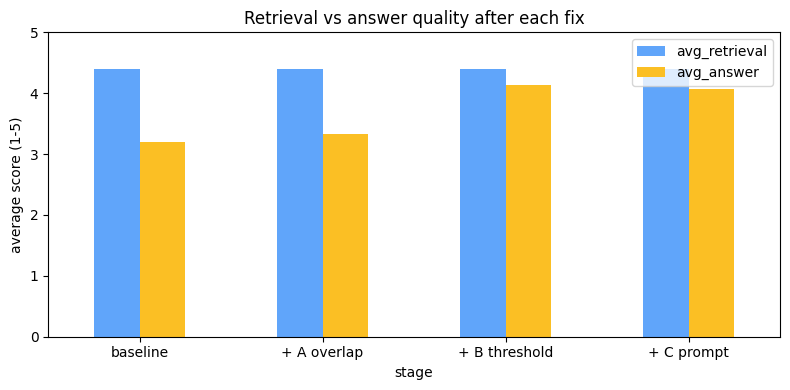

In [16]:
import matplotlib.pyplot as plt
stages = {"baseline": baseline, "+ A overlap": after_A, "+ B threshold": after_B, "+ C prompt": after_C}
summary = pd.DataFrame([{"stage": k, "avg_retrieval": scorecard(v)["retrieval_score"].mean(), "avg_answer": scorecard(v)["answer_score"].mean(),
                         "passes": int((v["diagnosis"] == "PASS").sum())} for k, v in stages.items()]).round(2)
print(summary.to_string(index=False))
ax = summary.set_index("stage")[["avg_retrieval", "avg_answer"]].plot(kind="bar", ylim=(0, 5), figsize=(8, 4), rot=0, color=["#60a5fa", "#fbbf24"])
ax.set_ylabel("average score (1-5)"); ax.set_title("Retrieval vs answer quality after each fix")
plt.tight_layout(); plt.savefig("day16_scorecard.png", dpi=150); plt.show()

In [17]:
baseline.to_csv("failure_classification_baseline.csv", index=False)
failure_table.to_csv("failure_table.csv", index=False)
summary.to_csv("scorecard_summary.csv", index=False)
print("saved: rag_results.json, failure_classification_baseline.csv, failure_table.csv, scorecard_summary.csv, day16_scorecard.png")
print("log entries:", len(LOG))

saved: rag_results.json, failure_classification_baseline.csv, failure_table.csv, scorecard_summary.csv, day16_scorecard.png
log entries: 60


In [18]:
manual_cause = {
    "Q09": "The referral chunks were retrieved, but the model gave the reward to the referred friend instead of the referrer: an answer-context mismatch.",
    "Q15": "Retrieval was correct, but the answer says Pro costs 800 and then 301 more, a reasoning error my substring check missed.",
}
answer_override = {"Q15": 1}
failure_table = baseline[["id", "mode", "query", "diagnosis", "cause"]].copy()
failure_table["cause"] = [manual_cause.get(i, c) for i, c in zip(failure_table["id"], failure_table["cause"])]
failure_table.loc[failure_table["id"] == "Q09", "diagnosis"] = "Answer-context mismatch"
failure_table.loc[failure_table["id"] == "Q15", "diagnosis"] = "Correct chunk, wrong answer"
failure_table.to_csv("failure_table.csv", index=False)
sc = scorecard(baseline)
print(f"Corrected baseline answer average: {sc['answer_score'].mean():.2f} / 5")

Corrected baseline answer average: 2.93 / 5


## 13. Written findings

**Failure map (baseline, 15 queries):** 7 passed and 8 failed. I also reviewed the passes by hand and found one more hidden failure (Q15), so the real count is 9 failures.

| Mode I targeted | What actually happened |
|---|---|
| Retrieval failure | Q03 failed. Q01 and Q02 passed because the top 3 chunks happened to include both halves of the split sentence. Q06 also failed on retrieval. |
| Context window overflow | Q04 failed (context cut by the 100-word budget). Q05 passed. |
| Answer-context mismatch | Q07, Q08 and Q09 all failed: the model answered something that is not in the documents. |
| Vague context retrieved | No real failure. The model correctly refused Q10, Q11 and Q12 even without a threshold. |
| Correct chunk, wrong answer | Q13 and Q14 failed. Q15 passed my automatic check but is actually wrong (see below). |

**Two corrections to the automatic labels**
- **Q09** was labelled "vague context" only because its best distance was high (L2 1.346). The referral chunks were retrieved. The model gave the free month to the *referred friend*, but the document gives it to the *farmer who refers*. This is an answer-context mismatch.
- **Q15** passed because my check only looks for the string "800" in the answer. The answer says the Pro plan costs 800 and then "301 more", which is a reasoning error. A substring check cannot catch this. I count it as "correct chunk, wrong answer".

**Two failures traced to a chunking or embedding decision**
1. **Q03, "Which languages does Kesar support?" (chunking decision).** With chunk_size=40 and overlap=0, the sentence "three languages: Urdu, Kashmiri | and English" is cut between chunk 8 and chunk 9. `trace_chunking()` showed no chunk holds the whole fact. Chunk 8 ranked #1, but chunk 9 (with "English") ranked #4 at L2 1.716, outside the top 3. The model answered "Urdu, Kashmiri" and dropped English.
2. **Q06, "List every support, maintenance and refund detail" (chunking and embedding).** The top 6 chunks were [2, 3, 8, 4, 5, 6]. Chunk 7, holding the support hours and the Sunday maintenance window, was left out. That chunk is the second half of the support document, cut away from chunk 6 by the chunker. The generic wording of the query also ranked chunk 2 (the flagship product sentence) first, so the query matched general product text instead of the support details. The model replied "I don't know".

**A third finding: truncation causes hallucination (Q04).** All needed facts were retrieved, but the 100-word budget cut chunks [3, 5, 2, 7]. The model then invented "999 rupees" for the Pro plan and "once every 6 months" for imagery refresh. When the context is cut, the model fills the gap with guesses.

**Fixes implemented and measured**

| Stage | Avg retrieval | Avg answer | Passes (of 15) |
|---|---|---|---|
| Baseline | 4.40 | 3.20 | 7 |
| + A: overlap 15 | 4.40 | 3.33 | 8 |
| + B: similarity threshold | 4.40 | 4.13 | 11 |
| + C: refined prompt | 4.40 | 4.07 | 11 |

- **Fix A (overlap)** fixed Q03: the sentence now appears whole in one chunk. But it also made other queries worse: Q01 became a context overflow (overlapping chunks are longer, so more of them were cut by the word budget) and Q12 started answering instead of refusing. Overlap trades against the context budget.
- **Fix B (threshold 0.878)** made Q07, Q09 and Q12 correct refusals. It refused 6 of 6 unanswerable queries but wrongly refused one answerable query (Q13). The ranges overlap (farthest good retrieval 0.936, closest unanswerable 0.890), so no threshold is perfect. Q07 passed by a margin of only 0.012 (0.89 vs 0.878).
- **Fix C (refined prompt)** changed no diagnoses. On a 1.5B model, a stricter prompt did not help measurably.

**Scorecard note:** retrieval stayed at 4.40 because the gains and losses cancelled out. Answer quality rose mostly because of the threshold. With Q15 corrected to 1, the baseline answer average is 2.93.

**What is still broken**
- Q08 ("Anantnag office staff") still answers "12": its best chunk (L2 0.789) is closer than the threshold, so a distance cut-off cannot catch a missing detail inside a relevant chunk.
- Q13 and Q14 are reasoning failures (42 - 12 and 10 x 1,299 = 12,990 / 10 months): the context is right, but the small model cannot do the arithmetic.
- Q04 and Q06 need a larger context budget or smarter chunk selection.

**Limits of this analysis:** the threshold was tuned on the same 15 queries it was tested on, so its gain is optimistic. The scores come from a written rubric, not human judgement. The model is small (1.5B), so some failures are about the model, not about RAG.

**Next steps:** a larger model, a context budget sized to the chunks, sentence-aware chunking instead of a fixed word window, and a check that the answer is supported by a quoted sentence.
